# 03 - Exploratory Data Analysis 

In [ ]:
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    CountVectorizer,
)
from sklearn.feature_selection import mutual_info_classif

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "../data/processed"
FIG_DIR = ROOT / "../reports/figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TEXT_COL = "text"
TARGET_COL = "is_unfair"

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load the three splits

In [2]:
def load_split(name):
    p = DATA_DIR / f"{name}.csv"
    if p.exists():
        return pd.read_csv(p)
    raise FileNotFoundError(f"No {name}.csv in {DATA_DIR}")

splits = {"train": load_split("train"), "val": load_split("val"), "test": load_split("test")}
train, val, test = splits["train"], splits["val"], splits["test"]

CAT_COLS = [c for c in train.columns if c not in (TEXT_COL, TARGET_COL)]
print("Category columns:", CAT_COLS)
for k, v in splits.items():
    print(k, v.shape)

Category columns: ['Limitation of liability', 'Unilateral termination', 'Unilateral change', 'Content removal', 'Contract by using', 'Choice of law', 'Jurisdiction', 'Arbitration']
train (5378, 10)
val (2275, 10)
test (1607, 10)


## 2. Data audit: shape, nulls, duplicates, cross-split overlap

In [3]:
rows = []
for k, df in splits.items():
    rows.append({
        "split": k,
        "rows": len(df),
        "null_cells": int(df.isna().sum().sum()),
        "empty_texts": int((df[TEXT_COL].fillna("").str.strip() == "").sum()),
        "duplicate_texts": int(df[TEXT_COL].duplicated().sum()),
        "unfair_rate_%": round(df[TARGET_COL].mean() * 100, 2),
    })
audit = pd.DataFrame(rows).set_index("split")
display(audit)

train_set, val_set, test_set = (set(d[TEXT_COL]) for d in (train, val, test))
overlap = pd.DataFrame({
    "pair": ["train & val", "train & test", "val & test"],
    "shared_texts": [len(train_set & val_set), len(train_set & test_set), len(val_set & test_set)],
})
display(overlap)

dtypes = pd.DataFrame({
    "train": train.dtypes.astype(str),
}).T
dtypes

,rows,null_cells,empty_texts,duplicate_texts,unfair_rate_%
split,,,,,
train,5378,0,0,0,11.47
val,2275,0,0,14,10.11
test,1607,0,0,7,10.70


,pair,shared_texts
0,train & val,0
1,train & test,0
2,val & test,8


,text,Limitation of liability,Unilateral termination,Unilateral change,Content removal,Contract by using,Choice of law,Jurisdiction,Arbitration,is_unfair
train,object,int64,int64,int64,int64,int64,int64,int64,int64,int64


## 3. Target distribution and leakage check

,train,val,test
is_unfair,,,
0,4761,2045,1435
1,617,230,172


,train,val,test
is_unfair,,,
0,88.53,89.89,89.3
1,11.47,10.11,10.7


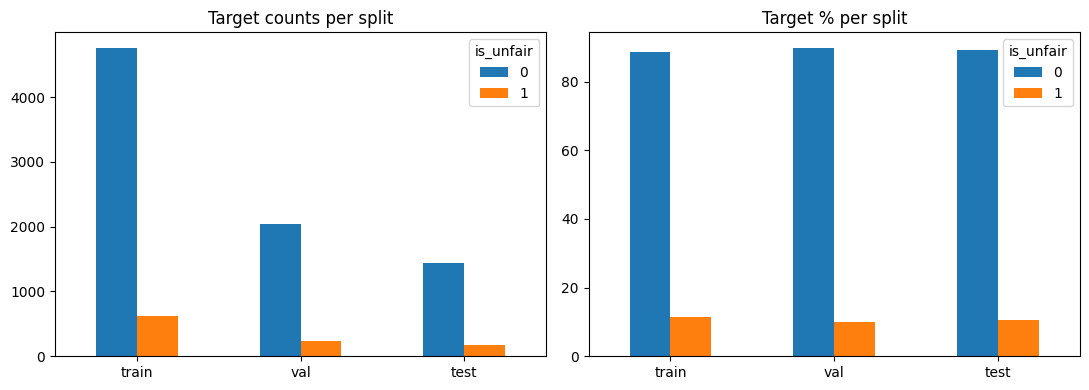

In [4]:
bal = pd.concat({k: d[TARGET_COL].value_counts().sort_index() for k, d in splits.items()}, axis=1).fillna(0).astype(int)
bal_pct = (bal / bal.sum() * 100).round(2)
display(bal)
display(bal_pct)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bal.T.plot(kind="bar", ax=ax[0], rot=0)
ax[0].set_title("Target counts per split")
ax[0].set_xlabel("")

bal_pct.T.plot(kind="bar", ax=ax[1], rot=0)
ax[1].set_title("Target % per split")
ax[1].set_xlabel("")
savefig("01_target_distribution")

## 4. Category columns

,train_count,train_%_of_all,train_%_of_unfair
Limitation of liability,188,3.50,30.47
Unilateral termination,136,2.53,22.04
Unilateral change,119,2.21,19.29
Contract by using,75,1.39,12.16
Content removal,72,1.34,11.67
Choice of law,36,0.67,5.83
Jurisdiction,34,0.63,5.51
Arbitration,28,0.52,4.54


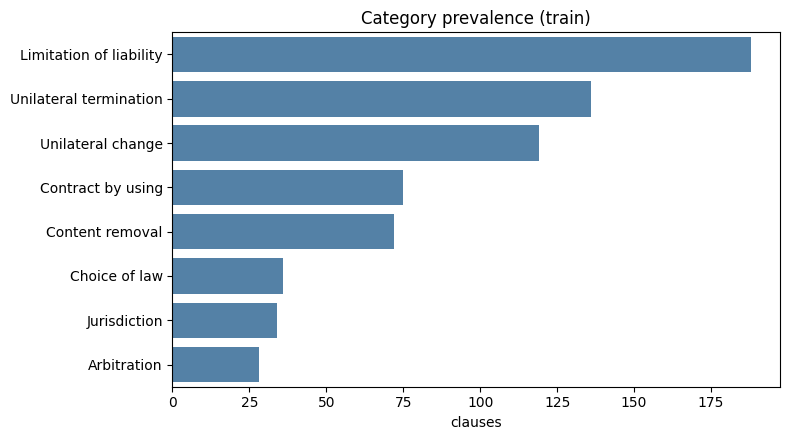

In [5]:
prev = pd.DataFrame({
    "train_count": train[CAT_COLS].sum(),
    "train_%_of_all": (train[CAT_COLS].mean() * 100).round(2),
    "train_%_of_unfair": (train.loc[train[TARGET_COL] == 1, CAT_COLS].mean() * 100).round(2),
}).sort_values("train_count", ascending=False)
display(prev)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=prev["train_count"], y=prev.index, ax=ax, color="steelblue")
ax.set_title("Category prevalence (train)"); ax.set_xlabel("clauses"); ax.set_ylabel("")
savefig("02_category_prevalence")

,clauses
0,4761
1,555
2,53
3,9


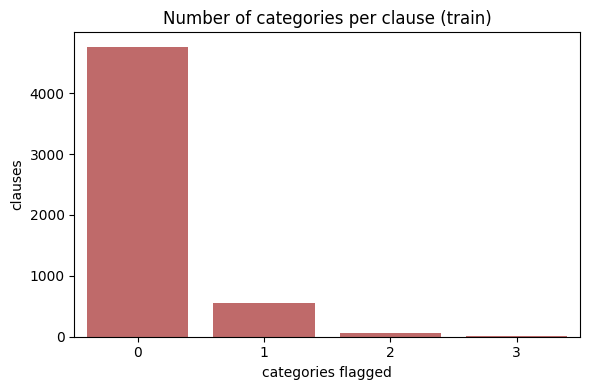

In [6]:
# how many categories are flagged per clause
n_cats = train[CAT_COLS].sum(axis=1)
n_cats_tab = n_cats.value_counts().sort_index().to_frame("clauses")
display(n_cats_tab)

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=n_cats_tab.index, y=n_cats_tab["clauses"], ax=ax, color="indianred")
ax.set_title("Number of categories per clause (train)"); ax.set_xlabel("categories flagged")
savefig("03_labels_per_clause")

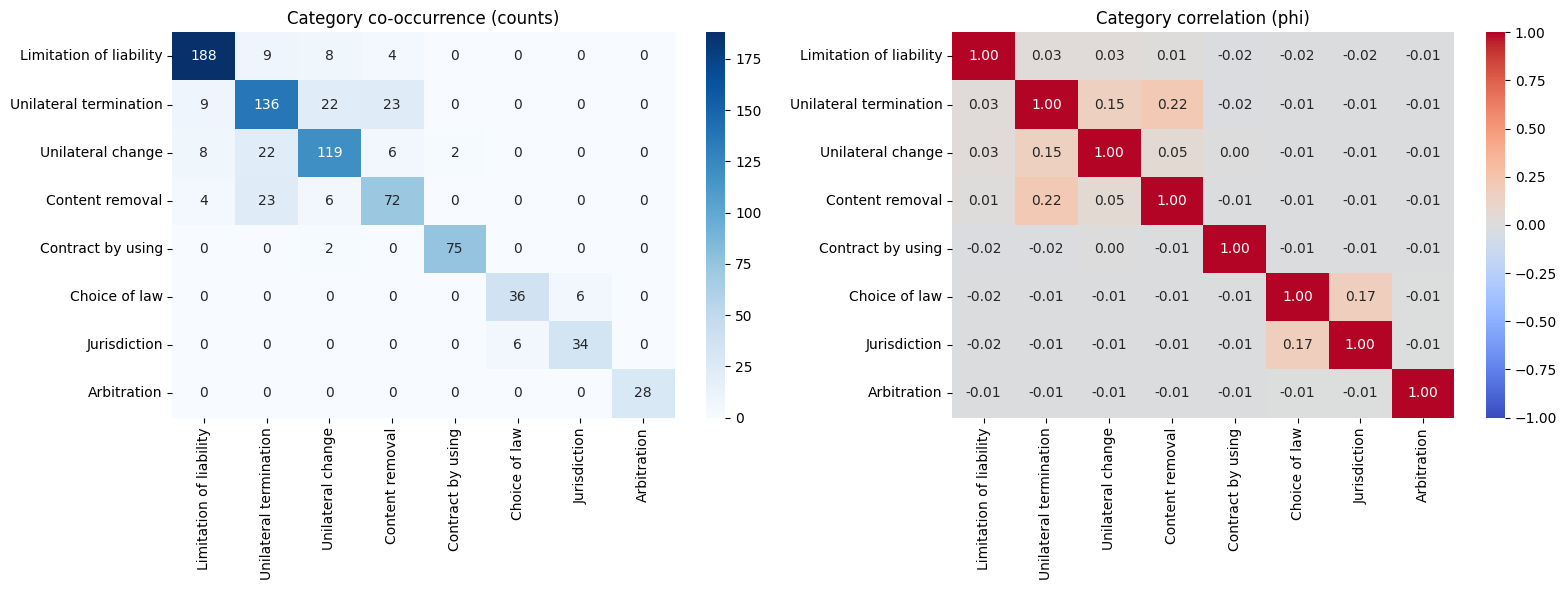

,Limitation of liability,Unilateral termination,Unilateral change,Content removal,Contract by using,Choice of law,Jurisdiction,Arbitration
VIF,1.0,1.07,1.03,1.05,1.0,1.03,1.03,1.0


In [7]:
cooc = train[CAT_COLS].T.dot(train[CAT_COLS])
phi = train[CAT_COLS].corr(method="pearson")

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cooc, annot=True, fmt="d", cmap="Blues", ax=ax[0]); ax[0].set_title("Category co-occurrence (counts)")
sns.heatmap(phi, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax[1]); ax[1].set_title("Category correlation (phi)")
savefig("04_category_cooccurrence_and_phi")

corr_mat = phi.values
vif = pd.Series(np.diag(np.linalg.pinv(corr_mat)), index=CAT_COLS, name="VIF").round(2)
display(vif.to_frame().T)

- A small correlation between `Unilateral change` and `Unilateral termination` is observed (0.22) which is expected since both lead to a change in the condition of the contract without any notice or consent.

## 5. Text statistics (train, compared with val/test)

In [8]:
def add_text_feats(df):
    t = df[TEXT_COL].fillna("")
    out = df.copy()
    out["char_len"] = t.str.len()
    out["word_count"] = t.str.split().str.len()
    out["sent_count"] = t.apply(lambda s: max(1, len(re.findall(r"[.!?]+", s))))
    return out

train, val, test = add_text_feats(train), add_text_feats(val), add_text_feats(test)
splits = {"train": train, "val": val, "test": test}

rows = []
for col in ["char_len", "word_count", "sent_count"]:
    x = train[col]
    rows.append({"feature": col, "mean": x.mean(), "median": x.median(), "std": x.std(),
                 "min": x.min(), "max": x.max(), "skew": stats.skew(x), "kurtosis": stats.kurtosis(x)})
text_stats = pd.DataFrame(rows).set_index("feature").round(2)
display(text_stats)

by_class = train.groupby(TARGET_COL)[["char_len", "word_count", "sent_count"]].describe().round(2)
display(by_class)

,mean,median,std,min,max,skew,kurtosis
feature,,,,,,,
char_len,178.82,146.0,135.57,13,2533,3.69,32.19
word_count,32.56,27.0,24.90,6,441,3.73,30.89
sent_count,1.21,1.0,0.67,1,9,4.52,26.18


char_len                                                     \
             count    mean     std   min    25%    50%    75%     max   
is_unfair                                                               
0           4761.0  172.58  128.33  13.0   93.0  142.0  214.0  2533.0   
1            617.0  226.92  174.82  26.0  125.0  179.0  273.0  1887.0   

          word_count         ...              sent_count                   \
               count   mean  ...   75%    max      count  mean   std  min   
is_unfair                    ...                                            
0             4761.0  31.34  ...  39.0  441.0     4761.0  1.21  0.68  1.0   
1              617.0  42.00  ...  50.0  353.0      617.0  1.18  0.59  1.0   

                               
           25%  50%  75%  max  
is_unfair                      
0          1.0  1.0  1.0  9.0  
1          1.0  1.0  1.0  5.0  

[2 rows x 24 columns]

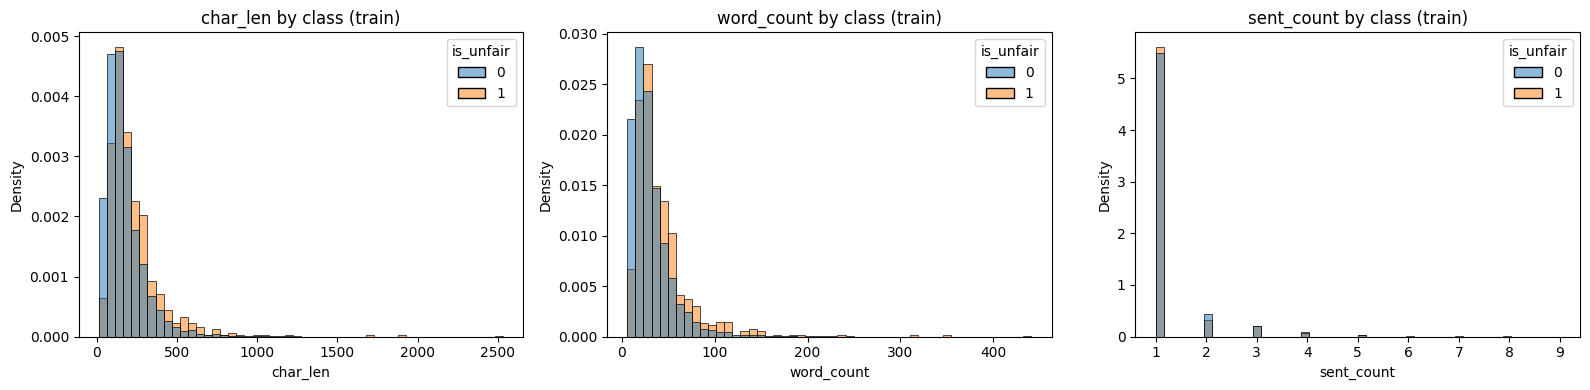

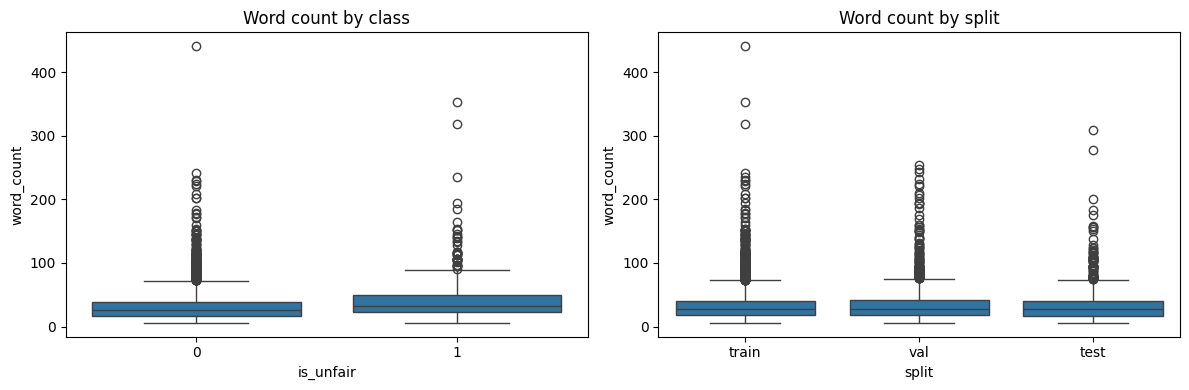

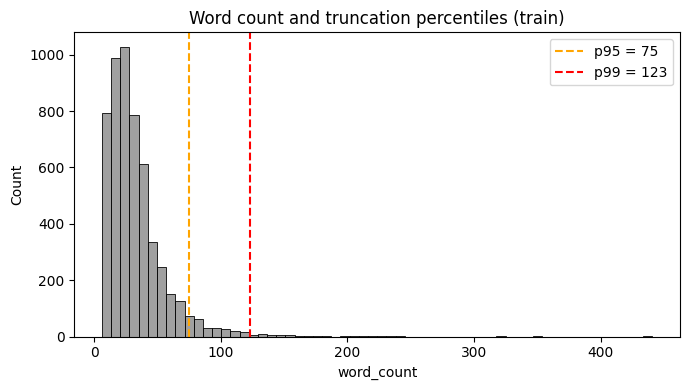

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ["char_len", "word_count", "sent_count"]):
    sns.histplot(data=train, x=col, hue=TARGET_COL, bins=50, kde=False, stat="density", common_norm=False, ax=a)
    a.set_title(f"{col} by class (train)")
savefig("05_text_length_by_class")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=train, x=TARGET_COL, y="word_count", ax=ax[0]); ax[0].set_title("Word count by class")
all_splits = pd.concat([d.assign(split=k) for k, d in splits.items()])
sns.boxplot(data=all_splits, x="split", y="word_count", ax=ax[1]); ax[1].set_title("Word count by split")
savefig("06_word_count_boxplots")

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(train["word_count"], bins=60, ax=ax, color="gray")
for q, c in [(0.95, "orange"), (0.99, "red")]:
    v = train["word_count"].quantile(q); ax.axvline(v, color=c, ls="--", label=f"p{int(q*100)} = {v:.0f}")
ax.legend(); ax.set_title("Word count and truncation percentiles (train)")
savefig("07_truncation_percentiles")

## 6. Vocabulary and signal (train only)

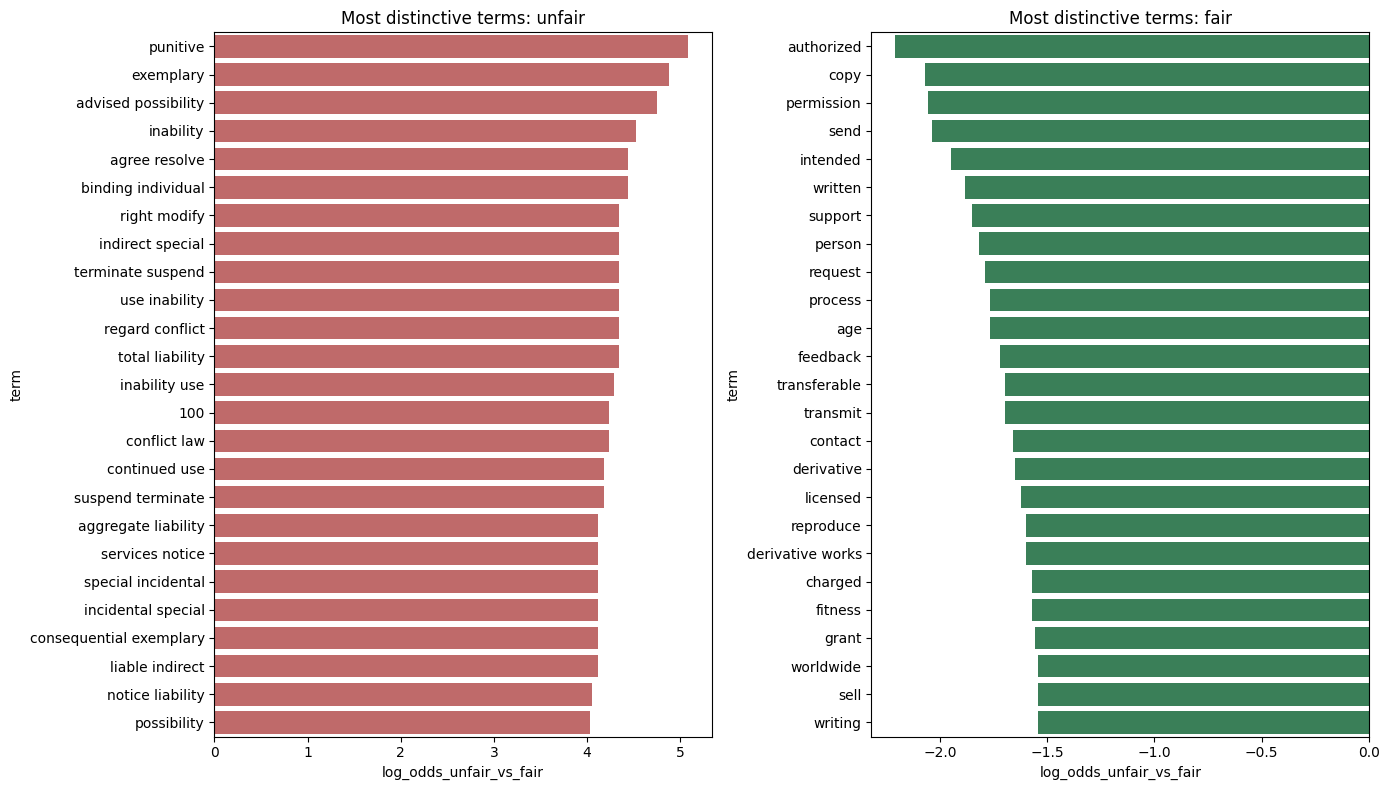

In [10]:
STOP = list(ENGLISH_STOP_WORDS)
cv = CountVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=5, binary=True, max_features=20000)
Xc = cv.fit_transform(train[TEXT_COL].fillna(""))
vocab = np.array(cv.get_feature_names_out())
y = train[TARGET_COL].values

df_pos = np.asarray(Xc[y == 1].sum(axis=0)).ravel()
df_neg = np.asarray(Xc[y == 0].sum(axis=0)).ravel()
n_pos, n_neg = (y == 1).sum(), (y == 0).sum()

log_odds = np.log((df_pos + 1) / (n_pos + 2)) - np.log((df_neg + 1) / (n_neg + 2))
lo = pd.DataFrame({"term": vocab, "log_odds_unfair_vs_fair": log_odds, "df_unfair": df_pos, "df_fair": df_neg})
top_unfair = lo.sort_values("log_odds_unfair_vs_fair", ascending=False).head(25)
top_fair = lo.sort_values("log_odds_unfair_vs_fair").head(25)

fig, ax = plt.subplots(1, 2, figsize=(14, 8))
sns.barplot(data=top_unfair, x="log_odds_unfair_vs_fair", y="term", ax=ax[0], color="indianred"); ax[0].set_title("Most distinctive terms: unfair")
sns.barplot(data=top_fair, x="log_odds_unfair_vs_fair", y="term", ax=ax[1], color="seagreen"); ax[1].set_title("Most distinctive terms: fair")
savefig("08_distinctive_terms_log_odds")

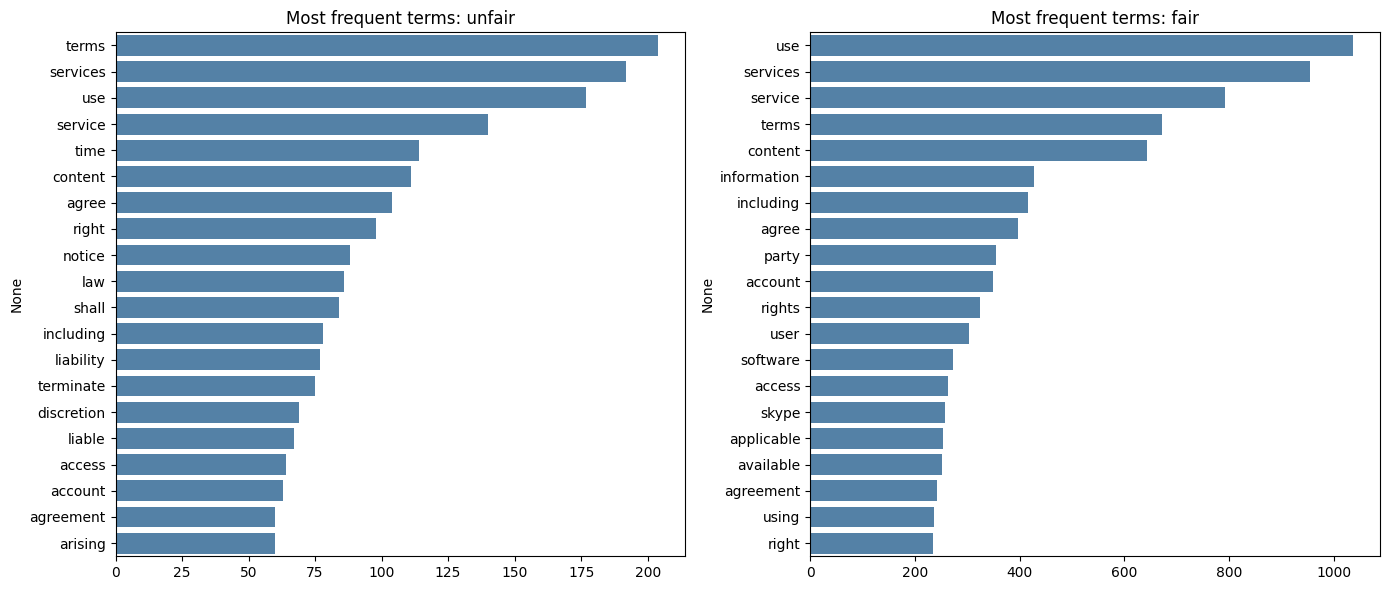

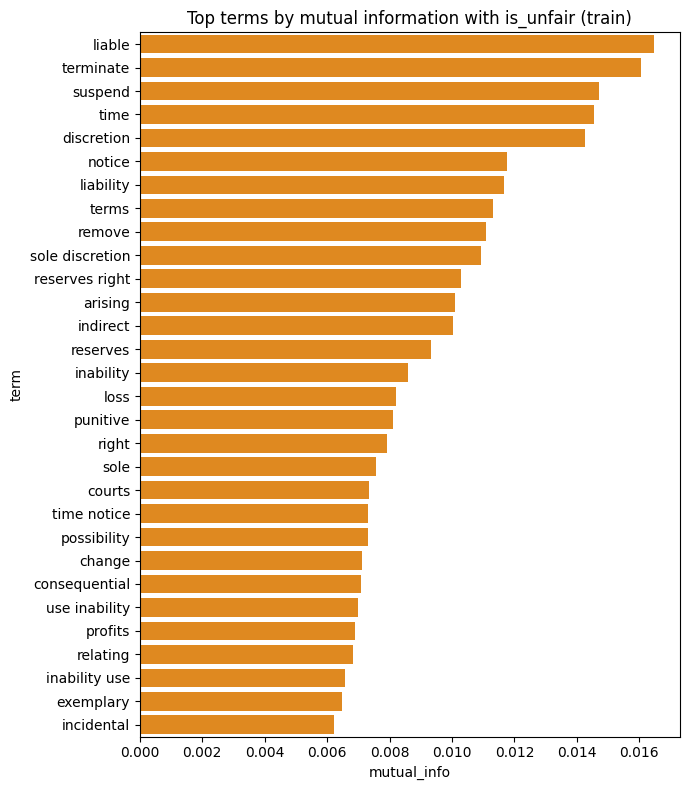

In [11]:
top_freq = {}
for label, name in [(1, "unfair"), (0, "fair")]:
    counts = np.asarray(Xc[y == label].sum(axis=0)).ravel()
    idx = counts.argsort()[::-1][:20]
    top_freq[name] = pd.Series(counts[idx], index=vocab[idx])

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, (name, s) in zip(ax, top_freq.items()):
    sns.barplot(x=s.values, y=s.index, ax=a, color="steelblue"); a.set_title(f"Most frequent terms: {name}")
savefig("09_top_frequent_terms")

mi = mutual_info_classif(Xc, y, discrete_features=True, random_state=RANDOM_STATE)
mi_df = pd.DataFrame({"term": vocab, "mutual_info": mi}).sort_values("mutual_info", ascending=False).head(30)

fig, ax = plt.subplots(figsize=(7, 8))
sns.barplot(data=mi_df, x="mutual_info", y="term", ax=ax, color="darkorange")
ax.set_title("Top terms by mutual information with is_unfair (train)")
savefig("10_mutual_information_terms")